# Comparación de modelos — IC por bootstrap

Notebook **reutilizable** para comparar modelos por sus métricas de validación
con intervalos de confianza (bootstrap *cluster* a nivel línea).

1. **Errorbar**: punto ± IC95% por métrica — la vista *fiel* al IC del bootstrap.
2. **Boxplot** con bigotes en los percentiles 2.5/97.5 (= el IC95%) + cuartiles.

In [9]:
import os
import sys
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detectar la raíz del repo (donde vive src/) y pararse ahí: así los paths
# relativos de los configs (data/..., configs/...) resuelven como en train.py.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training.save_model import (
    load_cached_results,
    results_cache_key,
    save_cached_results,
)
from src.training.run import run_evaluation
from src.utils.config import load_config
from src.utils.seed import set_seed

print("repo root:", ROOT)

repo root: c:\Users\MODDE\Desktop\Udesa\ML\PF\maze-genomic-pred


In [10]:
# === Modelos a comparar =====================================================
# Baseline GBLUP sin PCA, y DOS formas de elegir la dim de PCA (para ver cómo el
# método de selección cambia la conclusión):
#   (A) del SWEEP de wandb -> dim que maximiza Pearson en val 2019 (el MISMO set
#       donde después comparás): es lo estándar, pero el número del ganador queda
#       OPTIMISTA (winner's curse).
#   (B) ANIDADA -> dim elegida en un inner-val ANTERIOR (2018, train 2017) sin
#       tocar 2019: comparación honesta. Solo dims < ~900 (techo de rango p≫n).
from src.training.sweep import best_config_from_sweep, best_run_from_sweep
from src.training.select import config_with_nested_dim

SWEEP_PATH  = "oromagnoli-/maze-genomic-pred/ziu59tim"   # sweep de dim de PCA (split fijo)
PCA_BASE    = "configs/exp_pca_gblup_2017_2018_to_2019.yaml"
DIM_KEY     = "preprocess.pca.n_components"
NESTED_DIMS = [16, 32, 64, 128, 256, 512]                # elegibles en inner-2018 (n=901)

CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}

# (A) mejor del sweep — selección sobre val 2019 (OPTIMISTA)
try:
    ov, best_val, rid = best_run_from_sweep(SWEEP_PATH)
    a_dim = ov.get(DIM_KEY, "?")
    print(f"(A) sweep   -> dim={a_dim}  pearson_r_mean(val 2019)={best_val:.4f}  (run {rid})  [OPTIMISTA]")
    CONFIGS[f"PCA-{a_dim} (elegida en 2019)"] = best_config_from_sweep(SWEEP_PATH, PCA_BASE)
except Exception as e:
    print(f"[warn] no pude leer el sweep ({e}); salteo la opción (A)")

# (B) selección anidada — inner-val 2018, no toca 2019 (HONESTA)
cfg_nested, sel = config_with_nested_dim(PCA_BASE, DIM_KEY, NESTED_DIMS, inner_val_year=2018)
scores_2018 = {k: round(v, 3) for k, v in sel["scores"].items()}
print(f"(B) anidada -> dim={sel['best']}  (mejor en inner-2018; scores={scores_2018})  [HONESTA]")
CONFIGS[f"PCA-{sel['best']} (elegida en 2018)"] = cfg_nested

METRICS = ("pearson_r", "rmse", "r2")   # portada primero
N_BOOT = 2000      # réplicas de bootstrap (más = IC más estable)
ALPHA = 0.05       # IC del (1-alpha); 0.05 -> IC 95% (percentiles 2.5 / 97.5)

# Evita reentrenar modelos si ya hay resultados cacheados
USE_CACHE = True

FIG_DIR = ROOT / "experiments" / "figs"   
FIG_DIR.mkdir(parents=True, exist_ok=True)

(A) sweep   -> dim=1000  pearson_r_mean(val 2019)=0.3402  (run x00g6302)  [OPTIMISTA]
(B) anidada -> dim=128  (mejor en inner-2018; scores={16: 0.331, 32: 0.22, 64: 0.327, 128: 0.378, 256: 0.342, 512: 0.234})  [HONESTA]


In [11]:
import copy

def evaluate_model(name, config, *, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE):
    '''Corre run_evaluation (sin wandb) con bootstrap forzado y devuelve:
       - filas tidy [{model, metric, point, lo, hi}]
       - dict {metric: samples} con la distribución bootstrap por métrica.
    `config` puede ser una RUTA a un YAML o un dict de config ya armado (p.ej. el
    que devuelve best_config_from_sweep). Asume split fijo (un único fold de val).

    Con use_cache=True NO reentrena si ya hay resultados cacheados para esta
    (config, seed, n_boot, alpha): los levanta de disco. En miss evalúa y guarda.'''
    cfg = load_config(config) if isinstance(config, str) else copy.deepcopy(config)
    set_seed(int(cfg.get("seed", 575)))
    cfg.setdefault("bootstrap", {})
    cfg["bootstrap"].update(enabled=True, n_boot=n_boot, alpha=alpha)  # IC siempre on

    key = results_cache_key(cfg, n_boot=n_boot, alpha=alpha)
    res = load_cached_results(key) if use_cache else None
    if res is None:
        res = run_evaluation(cfg)              # sin log_fn => no toca wandb
        save_cached_results(key, res)          # cachea para las próximas corridas
    else:
        print(f"  [cache hit] {name} ({key})")

    fold = res["per_fold"][-1]                 # split fijo: el (único) fold de val
    boot = res["bootstrap"][-1] if res["bootstrap"] else {}

    rows, samples = [], {}
    for m in METRICS:
        rows.append({
            "model": name, "metric": m,
            "point": float(fold.get(m, np.nan)),
            "lo": float(fold.get(f"{m}_lo", np.nan)),
            "hi": float(fold.get(f"{m}_hi", np.nan)),
        })
        samples[m] = np.asarray(boot.get(m, []), dtype=float)
    return rows, samples

In [12]:
rows, samples_by_model = [], {}
for name, path in CONFIGS.items():
    r, s = evaluate_model(name, path)
    rows.extend(r)
    samples_by_model[name] = s
    print(f"[ok] {name}")

df = pd.DataFrame(rows)
df

  [cache hit] GBLUP sin PCA (REML) (90f1d6fe13802d36)
[ok] GBLUP sin PCA (REML)
  [cache hit] PCA-1000 (elegida en 2019) (2f368b7b9e73e0ec)
[ok] PCA-1000 (elegida en 2019)
[ok] PCA-128 (elegida en 2018)


,model,metric,point,lo,hi
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771
1,GBLUP sin PCA (REML),rmse,1.301634,1.239727,1.363143
2,GBLUP sin PCA (REML),r2,-0.664404,-0.873739,-0.490156
3,PCA-1000 (elegida en 2019),pearson_r,0.340193,0.274056,0.403527
4,PCA-1000 (elegida en 2019),rmse,1.301215,1.236220,1.364775
5,PCA-1000 (elegida en 2019),r2,-0.663332,-0.878916,-0.485362
6,PCA-128 (elegida en 2018),pearson_r,0.245375,0.180659,0.306936
7,PCA-128 (elegida en 2018),rmse,1.311948,1.250326,1.369933
8,PCA-128 (elegida en 2018),r2,-0.690886,-0.876803,-0.537228


In [13]:
# === Test PAREADO de la diferencia vs la REFERENCIA (modelo[0] = baseline) =====
# Comparar dos boxplots marginales NO dice si A le gana a B: se solapan por el
# ruido COMPARTIDO de qué líneas caen en val (afecta a los dos igual). Lo correcto
# es la diferencia sobre el MISMO resample: run_evaluation corre el bootstrap de
# cada modelo con la misma seed y el mismo grupo de líneas, así
# samples_X[b] - samples_ref[b] es un bootstrap PAREADO válido (ese ruido se
# cancela). Referencia = 1er modelo (baseline); comparamos cada otro contra él.
ref = list(samples_by_model)[0]
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in list(samples_by_model)[1:]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = samples_by_model[name][m], samples_by_model[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")
print("\nOJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su "
      "delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la "
      "comparación honesta. La adjudicación final es 2020, sellado.")


PCA-1000 (elegida en 2019)  -  GBLUP sin PCA (REML):
  pearson_r: delta = +0.0255  IC95% [+0.0025, +0.0489]  -> SIGNIFICATIVA
       rmse: delta = -0.0002  IC95% [-0.0230, +0.0216]  -> no significativa (IC incluye 0)
         r2: delta = +0.0004  IC95% [-0.0560, +0.0589]  -> no significativa (IC incluye 0)

PCA-128 (elegida en 2018)  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0689  IC95% [-0.1022, -0.0369]  -> SIGNIFICATIVA
       rmse: delta = +0.0102  IC95% [-0.0175, +0.0372]  -> no significativa (IC incluye 0)
         r2: delta = -0.0259  IC95% [-0.0941, +0.0451]  -> no significativa (IC incluye 0)

OJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la comparación honesta. La adjudicación final es 2020, sellado.


## 1) Errorbar — punto ± IC95%

La forma más fiel de mostrar el IC: el punto es la estimación sobre validación y
los bigotes son los percentiles 2.5 / 97.5 del bootstrap. Ideal para comparar
varios modelos de un vistazo.

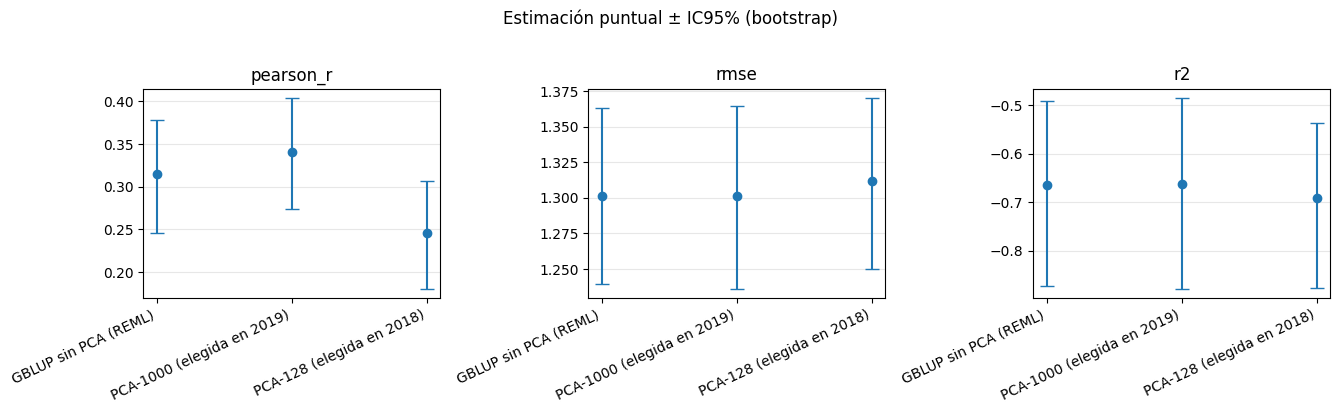

In [14]:
def plot_ci(df, metrics=METRICS, title="Estimación puntual ± IC95% (bootstrap)"):
    '''Un subplot por métrica; cada modelo como punto con bigotes [lo, hi].'''
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 4))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, metrics):
        sub = df[df.metric == m].reset_index(drop=True)
        x = np.arange(len(sub))
        point = sub["point"].to_numpy(float)
        lo = sub["lo"].to_numpy(float)
        hi = sub["hi"].to_numpy(float)
        # yerr no-negativo (el punto puede caer fuera del IC en distros sesgadas).
        yerr = np.vstack([np.maximum(point - lo, 0), np.maximum(hi - point, 0)])
        ax.errorbar(x, point, yerr=yerr, fmt="o", capsize=5, lw=1.5, color="tab:blue")
        ax.set_xticks(x)
        ax.set_xticklabels(sub["model"], rotation=25, ha="right")
        ax.set_title(m)
        ax.grid(True, axis="y", alpha=0.3)
    fig.suptitle(title, y=1.02, fontsize=12)
    fig.tight_layout()
    return fig


fig = plot_ci(df)
fig.savefig(FIG_DIR / "ci_errorbars.png", dpi=150, bbox_inches="tight")
plt.show()

## 2) Boxplot de la distribución bootstrap

Un boxplot por default pone los bigotes en 1.5·IQR, que **no** es tu IC. El truco:
`whis=(2.5, 97.5)` deja los bigotes exactamente en el **IC95%**. La caja sigue
mostrando los cuartiles (Q1 / mediana / Q3), así ves forma + IC juntos.
(Pearson del dummy es `nan` → se saltea solo.)

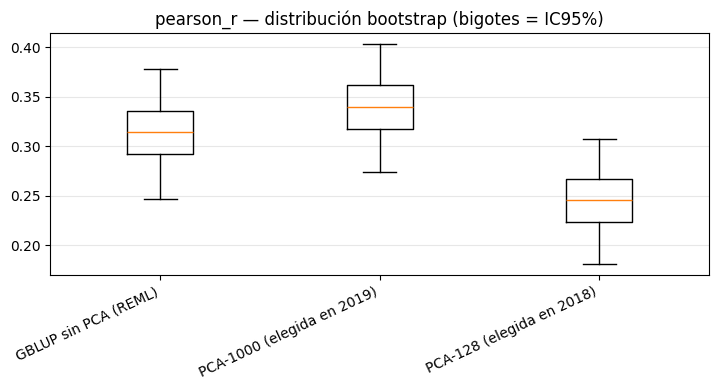

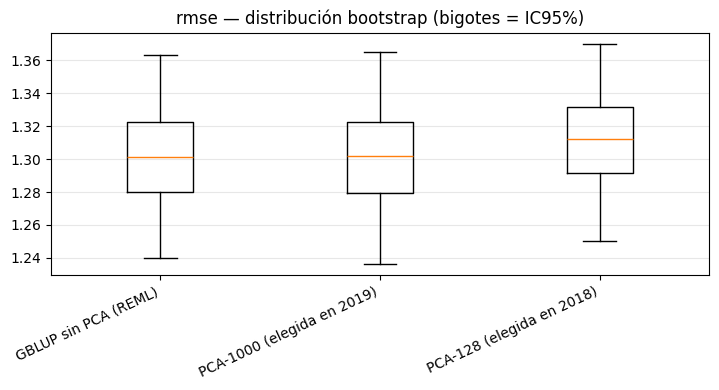

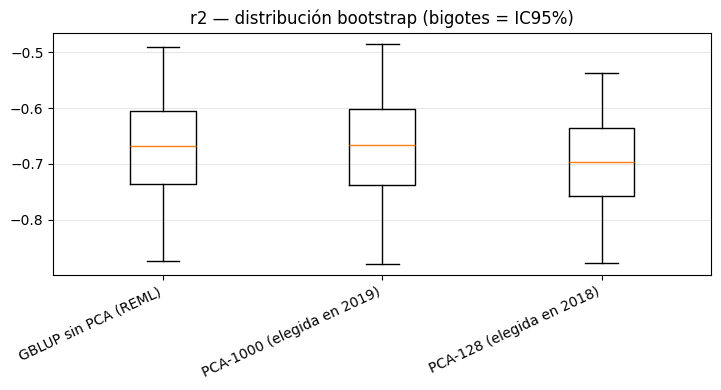

In [15]:
def plot_box(samples_by_model, metric, *, whis=(2.5, 97.5)):
    '''Boxplot de la distribución bootstrap. whis=(2.5, 97.5) => bigotes = IC95%.'''
    models = [k for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    data = [s[metric][np.isfinite(s[metric])]
            for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    if not data:
        print(f"(sin muestras finitas para {metric})")
        return None
    fig, ax = plt.subplots(figsize=(1.8 * len(models) + 2, 4))
    # `tick_labels` se llama `labels` en matplotlib < 3.9: elegir el kwarg vigente.
    import matplotlib as mpl
    label_kw = "tick_labels" if tuple(map(int, mpl.__version__.split(".")[:2])) >= (3, 9) else "labels"
    ax.boxplot(data, whis=whis, showfliers=False, **{label_kw: models})
    ax.set_title(f"{metric} — distribución bootstrap (bigotes = IC95%)")
    ax.grid(True, axis="y", alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    fig.tight_layout()
    return fig


for m in ("pearson_r","rmse", "r2"):
    fig = plot_box(samples_by_model, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

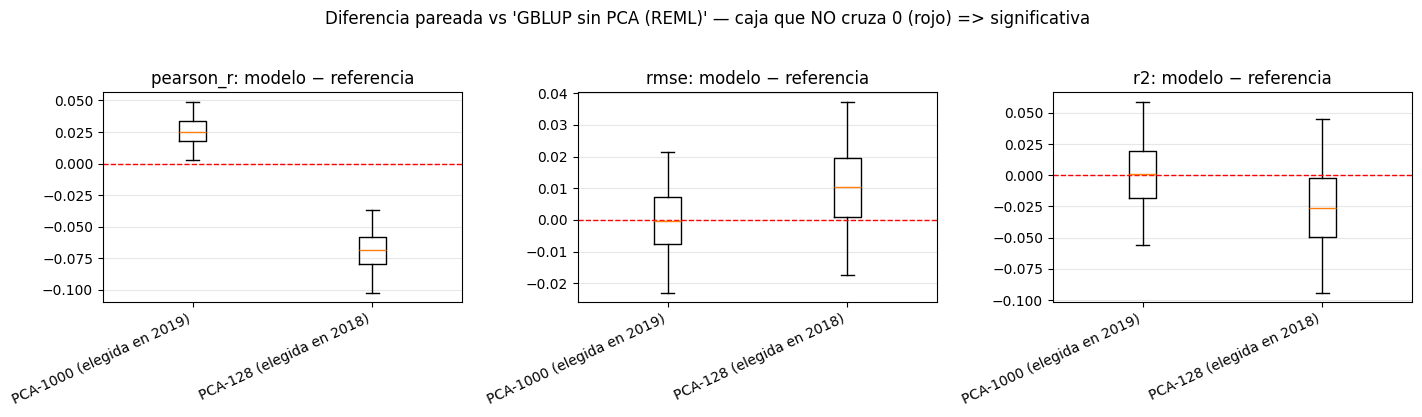

In [16]:
# === Boxplot de la DIFERENCIA pareada vs la referencia: ESTO sí mide significancia ==
# Una caja por (modelo - referencia) sobre el MISMO resample. Si la caja/bigotes
# (IC95%) NO cruzan el 0 (línea roja) => diferencia significativa. Signo: para
# Pearson/R² arriba de 0 = el modelo le gana al baseline; para RMSE es al revés.
# (Dos boxplots marginales "uno más arriba" NO alcanzan: se solapan por el ruido
#  compartido de val; la diferencia lo cancela y por eso se puede leer.)
ref = list(samples_by_model)[0]
others = list(samples_by_model)[1:]
fig, axes = plt.subplots(1, len(METRICS), figsize=(4.8 * len(METRICS), 4))
for ax, m in zip(np.atleast_1d(axes), METRICS):
    data = []
    for name in others:
        sx, sr = samples_by_model[name][m], samples_by_model[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n]); data.append(d[np.isfinite(d)])
    ax.boxplot(data, whis=(2.5, 97.5), showfliers=False)
    ax.set_xticks(range(1, len(others) + 1))
    ax.set_xticklabels(others, rotation=25, ha="right")
    ax.axhline(0, color="red", ls="--", lw=1)          # 'sin diferencia'
    ax.set_title(f"{m}: modelo − referencia")
    ax.grid(True, axis="y", alpha=0.3)
fig.suptitle(f"Diferencia pareada vs '{ref}' — caja que NO cruza 0 (rojo) => significativa", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "box_paired_diff.png", dpi=150, bbox_inches="tight")
plt.show()

## Notas

- **Un solo fold**: con el split fijo (train 2017-18 / val 2019) hay un único fold
  de validación; el notebook toma ese. El test 2020 queda intocable.
- **Reproducible**: el bootstrap usa la seed del config; misma config → mismo IC.
- **Caché**: con `USE_CACHE = True` cada modelo se evalúa una sola vez por
  (config, seed, `N_BOOT`, `ALPHA`); las corridas siguientes levantan el resultado
  de `outputs/eval_cache` sin reentrenar. Cambiar un hiperparámetro del config
  invalida su entrada sola; poné `USE_CACHE = False` para forzar recómputo.
- **Modelos entrenados**: para reusar un modelo/encoder sin reentrenar, `scripts/train.py` lo guarda como wandb
  Artifact + copia local; se carga con `load_model_artifact(...)` pasando los
  `train_years` del fold para que el chequeo anti-leakage corte cualquier fuga.
- **Figuras**: se guardan en `FIG_DIR` (`experiments/figs`, gitignored)